# C07e — Sapling: paired OG → NS10 commercial transfer

Score all **54 OG/NS10 pairs** with hosted Sapling. No human references, model training, GPU, or generation. Outcomes: paired mean/median AI-score reduction, improved/worsened/tied cases, paired bootstrap intervals, score scatter and **fraction flagged versus threshold** staircases. These are not ROC curves; human-versus-AI AUROC and FPR cannot be estimated from these inputs.

The explicit Sapling version is `20260820` (current default documented 2026-09-23). Scores closer to 1 indicate more AI-like text. This is transfer of fixed NS10 outputs, not proof of human-band alignment or quality. No detector adaptation is performed.

## Run
1. Open in `reproduction/` and run setup/data cells. Inspect actual character totals.
2. Get a trial key from https://sapling.ai/api_settings; enter it through the hidden prompt or `SAPLING_API_KEY` environment variable. Do not paste keys into saved notebook cells.
3. Set `RUN_API=True` in the submission cell. It sends full texts to Sapling. The documented free limits are 50,000 characters/day and 250,000/month; this notebook conservatively tracks attempts in rolling 24-hour/31-day windows. Account usage elsewhere must be entered separately. It never adds billing or upgrades your account.
4. When stopped by quota, rerun later; saved responses are reused. An interrupted HTTP request is counted conservatively and is not automatically retried.
5. Run analysis at any point: it reports complete pairs only and explicitly labels partial results. Final results require all 54 pairs.

If the total exceeds the monthly quota, finishing free will require another quota period or vendor-provided research credits. Do not shorten texts just to fit the quota. Quota records are local estimates, not a live account balance; retain the output directory across restarts.

Official docs: https://sapling.ai/docs/api/detector/ ; https://sapling.ai/docs/api/pricing/


In [1]:
from pathlib import Path
import os,json,hashlib,tempfile,time,getpass,fcntl
from datetime import datetime,timezone
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from IPython.display import display
ROOT_OVERRIDE=None
ROOT=Path(ROOT_OVERRIDE) if ROOT_OVERRIDE else next((p for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents] if (p/'results/causal/C02d2_fz118_ghostbuster_raid').exists()),None)
assert ROOT is not None,'Set ROOT_OVERRIDE to reproduction/.'
BASE=ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
NSDIR=ROOT/'results/causal/C06b_NEW_steps5_10_v1'
OUT=ROOT/'results/causal/C07e_Sapling_OG_NS10_v1'
for sub in ['', 'responses','attempts','figures']:(OUT/sub).mkdir(parents=True,exist_ok=True)
SPEC={'endpoint':'https://api.sapling.ai/api/v1/aidetect','version':'20260820','sent_scores':False,'score_string':False}
SEED=20260923
DAILY_CAP=50_000
MONTHLY_CAP=250_000
# Set these to conservative amounts used elsewhere on the same API account.
OTHER_USAGE_24H=0
OTHER_USAGE_31D=0

def sha(x):return hashlib.sha256(str(x).encode()).hexdigest()
def atomic_json(path,value):
    fd,tmp=tempfile.mkstemp(dir=path.parent,suffix='.tmp')
    try:
        with os.fdopen(fd,'w') as f:json.dump(value,f,indent=2,sort_keys=True,allow_nan=False);f.flush();os.fsync(f.fileno())
        os.replace(tmp,path)
    finally:
        if os.path.exists(tmp):os.unlink(tmp)
def key_for(text):return sha(json.dumps(SPEC,sort_keys=True)+sha(text))
def response_path(text):return OUT/'responses'/(key_for(text)+'.json')
def parse_score(body):
    value=body.get('score') if isinstance(body,dict) else None
    if isinstance(value,bool) or not isinstance(value,(int,float)) or not np.isfinite(value) or not 0<=value<=1:
        raise ValueError('Missing/invalid Sapling document score; inspect saved response, do not resubmit.')
    return float(value)
def attempts():return [json.loads(p.read_text()) for p in (OUT/'attempts').glob('*.json')]
def quota_remaining():
    records=attempts();now=time.time()
    daily=sum(r['characters'] for r in records if now-r['timestamp']<86400)
    monthly=sum(r['characters'] for r in records if now-r['timestamp']<31*86400)
    return max(0,DAILY_CAP-daily-OTHER_USAGE_24H),max(0,MONTHLY_CAP-monthly-OTHER_USAGE_31D)
print('Output:',OUT)


Output: ../results/causal/C07e_Sapling_OG_NS10_v1


In [2]:
meta=pd.read_parquet(BASE/'fz118_paired_features.parquet')
corpus=pd.read_parquet(BASE/'paired_corpus.parquet')
assert meta.source_id.is_unique and corpus.source_id.is_unique
raid=meta.loc[meta.dataset.eq('raid'),['source_id','split','label','domain']].merge(corpus[['source_id','text']],on='source_id',validate='one_to_one')
ns=pd.read_csv(NSDIR/'NS10_texts.csv',keep_default_na=False).sort_values('case_id').reset_index(drop=True)
ns['case_id']=ns.case_id.astype(str)
assert len(ns)==54 and ns.case_id.is_unique and ns.source_id.is_unique
assert ns.text.map(sha).eq(ns.text_sha).all()
r=raid.set_index('source_id')
assert r.loc[ns.source_id,'label'].eq(1).all() and r.loc[ns.source_id,'split'].eq('test').all()
assert r.loc[ns.source_id,'domain'].tolist()==ns.domain.tolist()
og=ns[['case_id','source_id','domain']].copy();og['text']=og.source_id.map(r.text)
og['arm']='OG';ns['arm']='NS10'
cols=['case_id','source_id','domain','arm','text']
docs=pd.concat([og[cols],ns[cols]],ignore_index=True)
assert docs.text.notna().all() and docs.text.str.strip().ne('').all()
docs['text_sha']=docs.text.map(sha);docs['characters']=docs.text.str.len()
assert docs.characters.le(200000).all(),'Sapling input limit exceeded; no automatic truncation.'
manifest={'spec':SPEC,'documents':docs.drop(columns='text').to_dict('records')}
p=OUT/'protocol.json'
if p.exists():assert json.loads(p.read_text())==manifest,'Actual inputs or API settings changed; use a new OUT.'
else:atomic_json(p,manifest)
docs.drop(columns='text').to_csv(OUT/'document_manifest.csv',index=False)
# Random case order; each pair remains adjacent. Randomize which arm goes first.
rng=np.random.default_rng(SEED);ordered=[]
for cid in rng.permutation(sorted(ns.case_id)):
    pair=docs.loc[docs.case_id.eq(cid)]
    ordered.extend(pair.iloc[rng.permutation(2)].to_dict('records'))
seen=set();queue=[]
for row in ordered:
    if row['text_sha'] not in seen:queue.append(row);seen.add(row['text_sha'])
pending=[row for row in queue if not response_path(row['text']).exists()]
display(docs.groupby('arm').agg(documents=('case_id','size'),characters=('characters','sum')))
print('Unique API requests:',len(queue),'| remaining:',len(pending))
print('Remaining characters:',sum(row['characters'] for row in pending))
print('Local remaining quota (24h, 31d):',quota_remaining())
print('Short documents (<300 chars, less detector signal):',int(docs.characters.lt(300).sum()))
if sum(row['characters'] for row in pending)>quota_remaining()[1]:print('Full run exceeds current local monthly allowance; another quota period or research credit is needed.')
del meta,corpus,r,raid


,documents,characters
arm,,
NS10,54,132621
OG,54,79110


Unique API requests: 108 | remaining: 97
Remaining characters: 191175
Local remaining quota (24h, 31d): (18814, 218814)
Short documents (<300 chars, less detector signal): 0


In [3]:
RUN_API=True # Set True to submit; no API key is stored in output files.
# If a request was interrupted before a response was saved, inspect the attempt
# and explicitly list its key here to retry. It remains counted against quota.
RETRY_UNCERTAIN_KEYS=[]
if not RUN_API:
    print('No requests sent. Set RUN_API=True when ready.')
else:
    with (OUT/'run.lock').open('a+') as lock:
        fcntl.flock(lock,fcntl.LOCK_EX|fcntl.LOCK_NB)
        session=requests.Session();api_key=None
        try:
            for row in queue:
                text=row['text'];p=response_path(text);key=key_for(text)
                if p.exists():
                    parse_score(json.loads(p.read_text())['response']);continue
                uncertain=[r for r in attempts() if r['key']==key and r['status'] in ['started','uncertain']]
                if uncertain and key not in RETRY_UNCERTAIN_KEYS:
                    print('Stopped: prior request outcome unknown for',row['case_id'],row['arm'],'key:',key);break
                daily,monthly=quota_remaining()
                if row['characters']>min(daily,monthly):
                    print('Quota pause before',row['case_id'],row['arm'],'| needed',row['characters'],'| remaining',daily,monthly);break
                if api_key is None:
                    api_key=os.environ.get('SAPLING_API_KEY') or getpass.getpass('Sapling API key (hidden): ')
                    assert api_key.strip(),'API key required.'
                    session.headers.update({'Content-Type': 'application/json'})
                stamp=time.time();ap=OUT/'attempts'/f'{time.time_ns()}_{key}.json'
                attempt={'key':key,'timestamp':stamp,'utc':datetime.now(timezone.utc).isoformat(),'characters':row['characters'],'case_id':row['case_id'],'arm':row['arm'],'status':'started'}
                atomic_json(ap,attempt) # Reserve quota before submitting, including uncertain outcomes.
                payload = {
                    'key': api_key.strip(),
                    'text': text,
                    **{k: v for k, v in SPEC.items() if k != 'endpoint'},
                }
                try:
                    response=session.post(SPEC['endpoint'],json=payload,timeout=(15,180))
                except requests.RequestException:
                    attempt['status']='uncertain';atomic_json(ap,attempt)
                    print('Network error; outcome unknown. No automatic retry. Saved key:',key);break
                attempt.update(status='success' if response.ok else 'http_error',http_status=response.status_code)
                atomic_json(ap,attempt)
                try:body=response.json()
                except ValueError:body={'unparsed_response':True}
                if not response.ok:
                    print('Stopped at HTTP',response.status_code,'— check API quota/access or input. Completed responses are saved.');break
                record={'text_sha':row['text_sha'],'spec':SPEC,'requested_at':attempt['utc'],'completed_at':datetime.now(timezone.utc).isoformat(),'response':body}
                atomic_json(p,record)
                parse_score(body)
                print(row['case_id'],row['arm'],'saved | remaining quota:',quota_remaining(),flush=True)
                time.sleep(.5)
        finally:
            session.headers.pop('Authorization',None);session.close();api_key=None
            fcntl.flock(lock,fcntl.LOCK_UN)
print('Cached:',sum(response_path(row['text']).exists() for row in queue),'/',len(queue))


Sapling API key (hidden):  ········


gate_0048 NS10 saved | remaining quota: (16164, 216164)
gate_0024 OG saved | remaining quota: (14543, 214543)
gate_0024 NS10 saved | remaining quota: (12344, 212344)
gate_0001 NS10 saved | remaining quota: (9831, 209831)
gate_0001 OG saved | remaining quota: (8832, 208832)
gate_0026 NS10 saved | remaining quota: (7383, 207383)
gate_0026 OG saved | remaining quota: (6422, 206422)
gate_0005 NS10 saved | remaining quota: (5374, 205374)
gate_0005 OG saved | remaining quota: (4476, 204476)
gate_0069 OG saved | remaining quota: (3710, 203710)
gate_0069 NS10 saved | remaining quota: (1729, 201729)
Quota pause before gate_0046 NS10 | needed 1919 | remaining 1729 201729
Cached: 22 / 108


PARTIAL: 11/54 complete pairs. Available unpaired documents: 0


,metric,estimate,ci_low,ci_high,cases,status
0,mean_reduction,0.54506,0.14435,0.86537,11,PARTIAL
1,median_reduction,0.78561,-0.02726,0.97666,11,PARTIAL


,cases,improved,worsened,unchanged,OG_mean,NS10_mean,OG_median,NS10_median
0,11,8,3,0,0.7749,0.22984,0.95469,0.08361


,threshold,OG_detection_rate,NS10_detection_rate,reduction_pp,ci_low_pp,ci_high_pp,detected_to_undetected,undetected_to_detected
0,0.10,0.8182,0.3636,45.4545,8.8636,81.8182,6,1
1,0.25,0.8182,0.1818,63.6364,18.1818,100.0000,8,1
2,0.50,0.8182,0.1818,63.6364,18.1818,100.0000,8,1
3,0.75,0.8182,0.1818,63.6364,18.1818,100.0000,8,1
4,0.90,0.7273,0.1818,54.5455,9.0909,90.9091,7,1
5,0.95,0.5455,0.1818,36.3636,-9.0909,81.8182,6,2
6,0.99,0.2727,0.0000,27.2727,0.0000,54.5455,3,0


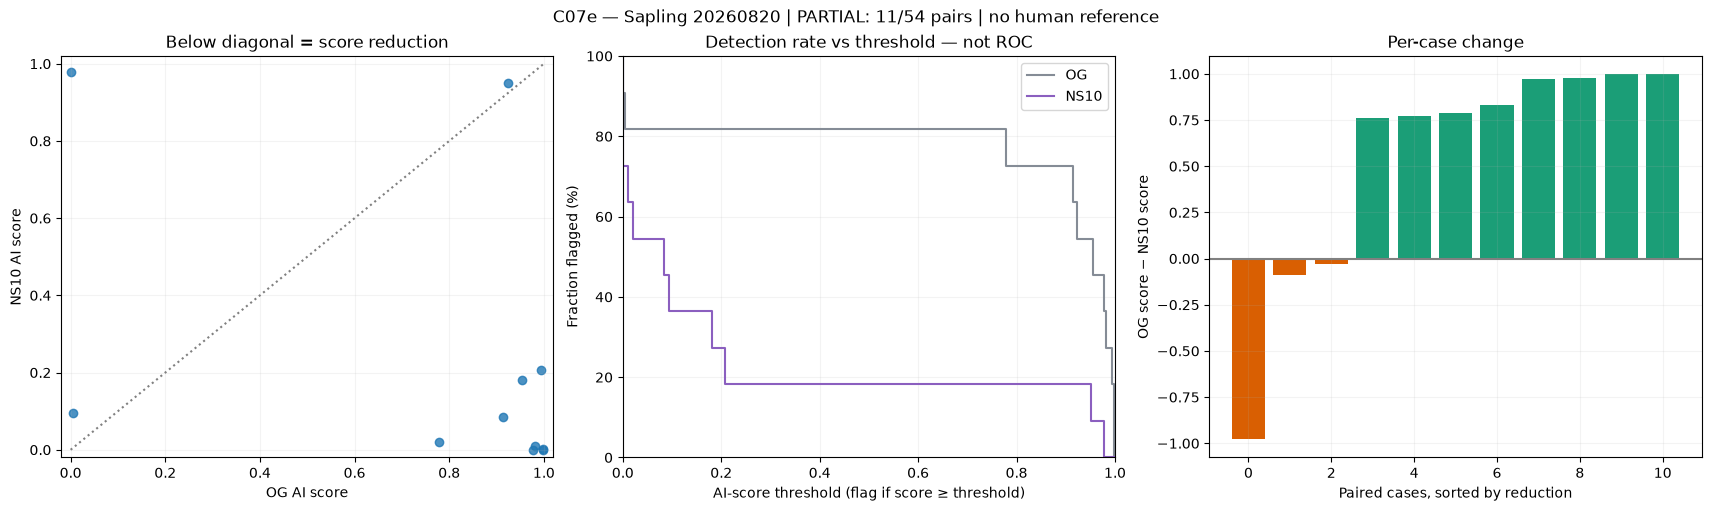

,cases,mean_reduction,median_reduction
domain,,,
abstracts,3,0.5254,0.7733
books,2,0.8647,0.8647
news,3,-0.0940,-0.0897
reddit,2,0.9872,0.9872
wiki,1,0.9978,0.9978


No human-vs-AI AUROC or FPR is estimated. Thresholds are prespecified diagnostics, not calibrated operating points.
CIs resample paired cases only; they exclude API/model drift and cohort-selection uncertainty. Partial samples are provisional.
Saved: ../results/causal/C07e_Sapling_OG_NS10_v1


In [4]:
rows=[]
for row in docs.to_dict('records'):
    p=response_path(row['text'])
    if p.exists():
        record=json.loads(p.read_text())
        rows.append({**{k:v for k,v in row.items() if k!='text'},'score':parse_score(record['response']),'requested_at':record['requested_at']})
assert rows,'No cached scores yet.'
scored=pd.DataFrame(rows);scored.to_csv(OUT/'scores_available.csv',index=False)
wide=scored.pivot(index='case_id',columns='arm',values='score').reindex(columns=['OG','NS10']).dropna()
assert len(wide),'No complete pairs yet; rerun submission later.'
wide=wide.join(ns.set_index('case_id')[['source_id','domain']])
wide['reduction']=wide.OG-wide.NS10 # Positive = lower AI score after intervention.
wide.to_csv(OUT/'paired_scores.csv')
n=len(wide);status='FINAL' if n==54 else 'PARTIAL'
print(f'{status}: {n}/54 complete pairs. Available unpaired documents:',len(scored)-2*n)
a=wide.OG.to_numpy();b=wide.NS10.to_numpy();d=a-b
rng=np.random.default_rng(SEED);ix=rng.integers(0,n,(10000,n));boot=d[ix]
metrics=[]
for name,value,samples in [('mean_reduction',d.mean(),boot.mean(axis=1)),('median_reduction',np.median(d),np.median(boot,axis=1))]:
    lo,hi=np.quantile(samples,[.025,.975]);metrics.append(dict(metric=name,estimate=value,ci_low=lo,ci_high=hi,cases=n,status=status))
summary=pd.DataFrame(metrics);summary.to_csv(OUT/'paired_summary.csv',index=False)
display(summary.round(5))
counts=pd.DataFrame([dict(cases=n,improved=int((d>0).sum()),worsened=int((d<0).sum()),unchanged=int((d==0).sum()),OG_mean=a.mean(),NS10_mean=b.mean(),OG_median=np.median(a),NS10_median=np.median(b))])
counts.to_csv(OUT/'direction_counts.csv',index=False);display(counts.round(5))
thresholds=np.unique(np.r_[0.,a,b,1.,np.nextafter(1.,np.inf)])
rates=pd.DataFrame({'threshold':thresholds,'OG_flagged_fraction':[(a>=t).mean() for t in thresholds],'NS10_flagged_fraction':[(b>=t).mean() for t in thresholds]})
rates.to_csv(OUT/'threshold_staircases.csv',index=False)
points=[]
for t in [.1,.25,.5,.75,.9,.95,.99]:
    before=a>=t;after=b>=t
    diff=before.astype(float)-after.astype(float);lo,hi=np.quantile(diff[ix].mean(axis=1),[.025,.975])
    points.append(dict(threshold=t,OG_detection_rate=before.mean(),NS10_detection_rate=after.mean(),reduction_pp=100*diff.mean(),ci_low_pp=100*lo,ci_high_pp=100*hi,detected_to_undetected=int((before&~after).sum()),undetected_to_detected=int((~before&after).sum())))
points=pd.DataFrame(points);points.to_csv(OUT/'threshold_summary.csv',index=False);display(points.round(4))
fig,axes=plt.subplots(1,3,figsize=(17,5),constrained_layout=True)
axes[0].scatter(a,b,alpha=.8);axes[0].plot([0,1],[0,1],':',color='gray');axes[0].set(xlim=(-.02,1.02),ylim=(-.02,1.02),xlabel='OG AI score',ylabel='NS10 AI score',title='Below diagonal = score reduction')
for arm,color in [('OG','#858C96'),('NS10','#8B5FBF')]:
    axes[1].step(thresholds,100*rates[arm+'_flagged_fraction'],where='pre',label=arm,color=color)
axes[1].set(xlim=(0,1),ylim=(0,100),xlabel='AI-score threshold (flag if score ≥ threshold)',ylabel='Fraction flagged (%)',title='Detection rate vs threshold — not ROC');axes[1].legend()
sort=np.argsort(d);axes[2].bar(np.arange(n),d[sort],color=np.where(d[sort]>=0,'#1B9E77','#D95F02'));axes[2].axhline(0,color='gray');axes[2].set(xlabel='Paired cases, sorted by reduction',ylabel='OG score − NS10 score',title='Per-case change')
for ax in axes:ax.grid(alpha=.15)
fig.suptitle(f'C07e — Sapling {SPEC["version"]} | {status}: {n}/54 pairs | no human reference')
for ext in ['png','pdf']:fig.savefig(OUT/'figures'/f'Sapling_paired_{n}.{ext}',dpi=220)
plt.show();plt.close(fig)
display(wide.groupby('domain').agg(cases=('reduction','size'),mean_reduction=('reduction','mean'),median_reduction=('reduction','median')).round(4))
print('No human-vs-AI AUROC or FPR is estimated. Thresholds are prespecified diagnostics, not calibrated operating points.')
print('CIs resample paired cases only; they exclude API/model drift and cohort-selection uncertainty. Partial samples are provisional.')
print('Saved:',OUT)
